**Red Neuronal Convolucional**

Describe qué es una red neuronal convolucional, en qué tipos de caso se aplica y cuál es su objetivo para esta actividad. Posteriormente copia los códigos fuente capturados en las imágenes y describe su funcionalidad agregando comentarios

# RED NEURONAL

Una red convolucional (CNN, Convolutional Neural Network) es un tipo de red neuronal diseñada principalmente para trabajar con datos que tienen una estructura espacial, especialmente imágenes. Se utilizan mucho en imagenes como clasificacion de imagenes, reconocimiento facial, vehiculos autonomos, deteccion de objetos, etc. Pero no necesariamente siempre son imagenens tambien puede ser en señales de audio o series temporales.
Su principal objetivo es aprender automaticamente características importantes de los datos para poder realizar una tarea de predicción o clasificacion.

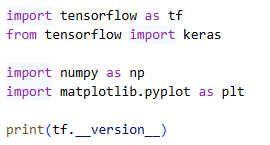

In [1]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo
import tensorflow as tf
from tensorflow import keras

import matplotlib.pyplot as plt
import numpy as np

print(tf.__version__)

# Hace importaciones de las principales librerias que se van a utilizar

I0000 00:00:1787355111.131325   58922 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1787355111.131718   58922 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1787355111.166525   58922 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1787355112.088185   58922 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

2.21.0


## 1. Preparar los datos

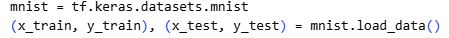

In [2]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Esta cargando un conjunto de datos de MNIST, es fundamental durante el aprendizaje de redes neuronales

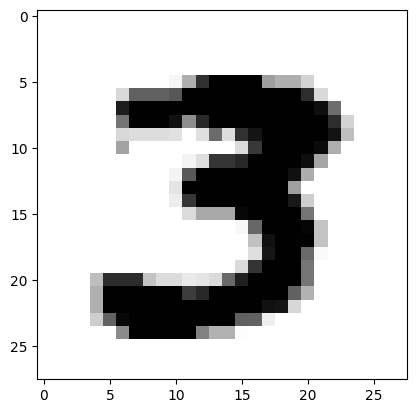

In [3]:
plt.imshow(x_train[27], cmap=plt.cm.binary)
# muestra la imagen de la posicion #27

image.png

In [4]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(y_train[27])
# muestra el resultado predicho

3


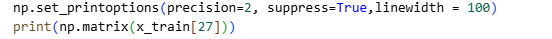

In [5]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
np.set_printoptions(precision=2, suppress=True, linewidth= 200)
print(np.matrix(x_train[27]))

# muestra una matriz de los valores de los píxeles correspondientes a la imagen número 28 del conjunto de entrenamiento de MNIST. Cada valor representa la intensidad de un píxel, donde los valores cercanos a 0 representan tonos oscuros y los cercanos a 255 representan tonos claros.

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   9  80 207 255 254 254 254  97  80  80  44   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  39 158 158 158 168 253 253 253 253 253 253 253 253 253 210  38   0   0   0   0   0   0]
 [  0   0   0   0   0   0 226 253 253 253 253 253 253 253 253 253 253 253 253 253 253 241 146   0   0   0   0   0]
 [  0   0   0   0   0   0 139 253 253 253 238 113 215 253 253 253 253 253 253 25

image.png

In [6]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(x_train.ndim)

# indica el numero de dimensiones, es decir es un arreglo tridimensional 

3


image.png

In [7]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(x_train.shape)
# aqui muestra el tamaño de cada dimension,  60000 imagenes de entrenamiento, 28 filas y 28 columnas

(60000, 28, 28)


image.png

In [8]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(x_train.dtype)
# indica el tipo de datos en este caso es uint8 significa Unsigned Integer de 8 bits

uint8


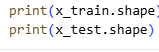

In [9]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(x_train.shape)
print(x_test.shape)

# imprime el tamaño de estructura de los arreglos  para x_train (60000 img-entrenamiento X 28-filas X 28-Columnas) y x_test (10000 img-prueba X 28-filas X 28-COLUMNAS)

(60000, 28, 28)
(10000, 28, 28)


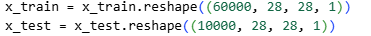
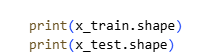

In [10]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
x_train = x_train.reshape((60000, 28, 28, 1))
x_test = x_test.reshape((10000, 28, 28, 1))

print(x_train.shape)
print(x_test.shape)

# cambia la estructura del arreglo, pero no cambia los valores de los pixeles, eneste caso el 1 representa el canal al ser escala de grises solo hay 1 si fuera a color seria 3 que representaria el RGB 


(60000, 28, 28, 1)
(10000, 28, 28, 1)


## 2. Preprocesado de los datos

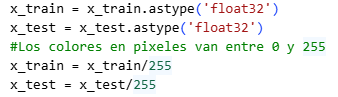

In [11]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train/255
x_test = x_test/255

# astype('float32') permite trabajar con numeros decimales y /255 normaliza los píxeles de un rango de 0 a 255 a 0 a 1, facilitando el entrenamiento de la red neuronal.

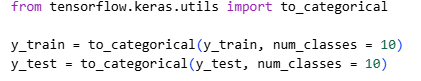

In [12]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
from tensorflow.keras.utils import to_categorical

y_train = to_categorical(y_train, num_classes = 10)
y_test = to_categorical(y_test, num_classes = 10)

# Convierte las etiquetas de los números del 0 al 9 a un formato de 10 posiciones, donde un 1 indica el número correspondiente y los demás valores son 0

image.png

In [13]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(y_test[27])
# muestra el resultado de la imagen de testeo 27, la cual muestra que es 4

[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


image.png

In [14]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(y_train[27])

# muestra el resultado de la imagen de entrenamiento, la cual muestra que es 3

[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


image.png

In [15]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(y_test.shape)

# imprime el resultado (10000, 10), porque hay 10,000 imágenes de prueba y cada etiqueta ahora tiene 10 posiciones, una por cada número del 0 al 9.

(10000, 10)


image.png

In [16]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print(y_train.shape)

# imprime el resultado (10000, 10), porque hay 10,000 imágenes de entrenamiento y cada etiqueta ahora tiene 10 posiciones, una por cada número del 0 al 9

(60000, 10)


## 3. Definición de modelo

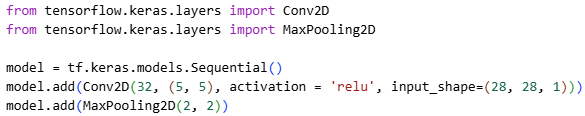

In [17]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D

model = tf.keras.models.Sequential()
model.add(Conv2D(32, (5, 5), activation = 'relu', input_shape=(28, 28, 1)))
model.add(MaxPooling2D(2, 2))

# La CNN comienza detectando caracteristicas de las imagenes mediante 32 filtros de 5×5 y después reduce su tamaño con MaxPooling 2×2 - conservando las caracteristicas mas importantes

/home/meme/Documentos/9no/ExtraccionDB/Database_Knowledge_Extraction/.venv/lib64/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1787355113.848806   58922 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


image.png

In [18]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
model.summary()
# muestra la arquitextura de la red neuronal la cual incluye las capas, parametros y estructura del modelo en general

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 832 (3.25 KB)

 Trainable params: 832 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

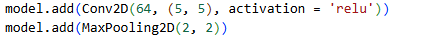

In [19]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
# una convolucional siempre va seguida de una maxpooling, explica por qué
model.add(Conv2D(64, (5,5), activation= 'relu'))
model.add(MaxPooling2D(2, 2))

# Agrega una segunda CNN con 64 filtros, permitiendo detectar características mas complejas, y luego reduce nuevamente el tamaño mediante MaxPooling 2×2.

image.png

In [20]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
model.summary()
# de nuevo muestra la arquitectura, la CNN tiene 2 capas convolucionales y 2 capas MaxPooling. Las convolucionales aumentan de 32 a 64 filtros para detectar características más complejas, mientras que MaxPooling reduce progresivamente el tamaño de las imágenes de 28×28 a 4×4.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,096 (203.50 KB)

 Trainable params: 52,096 (203.50 KB)

 Non-trainable params: 0 (0.00 B)

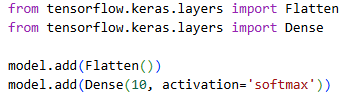

In [21]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense

model.add(Flatten())
model.add(Dense(10, activation='softmax'))
# Flatten convierte las caracteristicas en un vector y Dense realiza la clasificacion final en 10 clases, una por cada digito del 0 al 9

image.png

In [22]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
model.summary()
# muetra la estrctura final de la red Se agrega Flatten, que convierte 4×4×64 = 1024 caractersticas en un vector, y Dense genera 10 salidas, una por cada digito del 0 al 9. El modelo tiene 62,346 parametros en total

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,346 (243.54 KB)

 Trainable params: 62,346 (243.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Configuración del proceso de aprendizaje

image.png

In [23]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
model.compile(loss = "categorical_crossentropy", optimizer = "sgd", metrics = ["accuracy"])
# Configura la CNN usando categorical_crossentropy para calcular el error, SGD para ajustar los parametros y accuracy para medir la precision del modelo

## 5. Entrenamiento del modelo

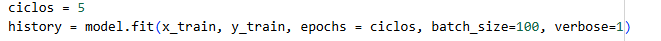

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
ciclos = 13
history = model.fit(x_train, y_train, epochs= ciclos, batch_size= 100, verbose= 1)

# se entrena el modelo en este caso durante 5 epocas la precision es de 0.9636 y la perdida  = 0.1277
# si son 10 epocas los resultados son;  precision = 0.9786 y perdida = 0.0728
# si son 15 epocas precision = 0.9870 y la perdida = 0.0436
# si son 20 epocas precision = 0.9915 y la perdida = 0.0293
# PERO A MEDIDA QUE AVANZA LA PERDIDA ES MAS NOTABLE POR ESA RAZON LO DEJE EN 13 EPOCAS ALIGUAL QUE INCREMENTAR SOLO PODRIA PROVAR UN OVERFITTING


Epoch 1/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9969 - loss: 0.0118
Epoch 2/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.9971 - loss: 0.0116
Epoch 3/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9972 - loss: 0.0115
Epoch 4/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9971 - loss: 0.0113
Epoch 5/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9972 - loss: 0.0109
Epoch 6/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9972 - loss: 0.0109
Epoch 7/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9976 - loss: 0.0104
Epoch 8/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9975 - loss: 0.0105
Epoch 9/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9975 - loss: 0.0107
Epoch 10/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9975 - loss: 0.0102
Epoch 11/13
600/600 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.9975 - loss: 0.0102
Epoch 12/13
600/600 ━━━━━━━━━━━━━

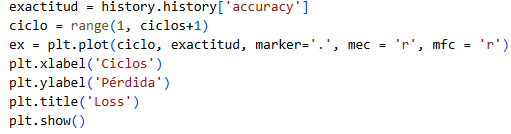

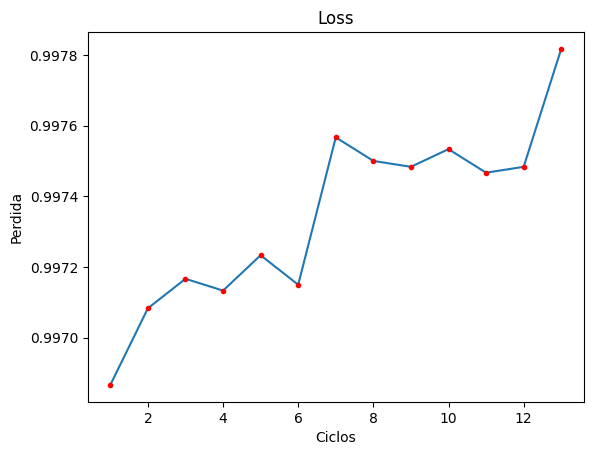

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
exactitud = history.history['accuracy']
ciclo = range(1, ciclos+1)
ex = plt.plot(ciclo, exactitud, marker='.', mec = 'r', mfc ='r')
plt.xlabel('Ciclos')
plt.ylabel('Perdida')
plt.title('Loss')
plt.show()

# La grafica muestra como cambia la exactitud del modelo durante los ciclos de entrenamiento. Si la exactitud aumenta - significa que el modelo esta aprendiendo y mejorando su clasificacion.

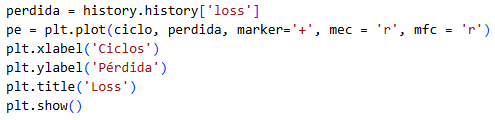

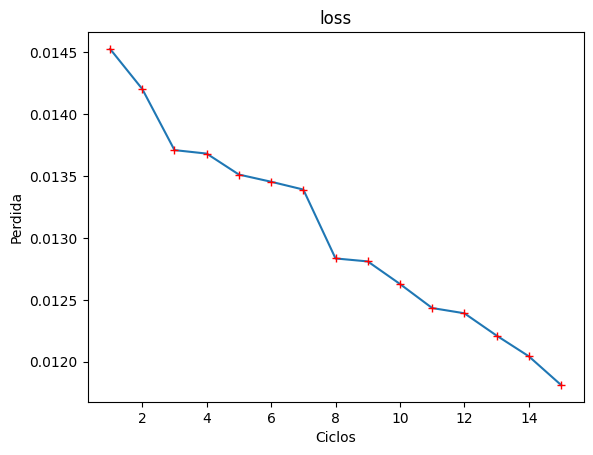

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
perdida = history.history['loss']
pe = plt.plot(ciclo, perdida, marker = '+', mec = 'r', mfc = 'r')
plt.xlabel('Ciclos')
plt.ylabel('Perdida')
plt.title('loss')
plt.show()
# # en este caso muestra la perdida de manera inversa si la grafica disminuye el modelo esta mejorando y no se equivoca, sin embargo no hay que exagerar ya que puede aprender los datos de entrenamiento pero con datos de prueba puede ser un fracaso

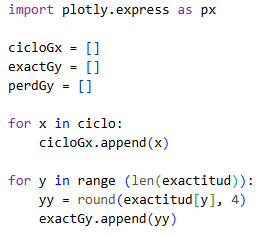

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
import plotly.express as px

cicloGx = []
exactGy = []
perdGy = []

for x in ciclo:
    cicloGx.append(x)

for y in range (len(exactitud)):
    yy = round(exactitud[y], 4)
    exactGy.append(yy)

cicloGx = list(range(1, len(exactGy) + 1))

# Prepara las listas de ciclos y exactitud para utilizarlas posteriormente en una grafica con Plotly, redondeando la exactitud a 4 decimales

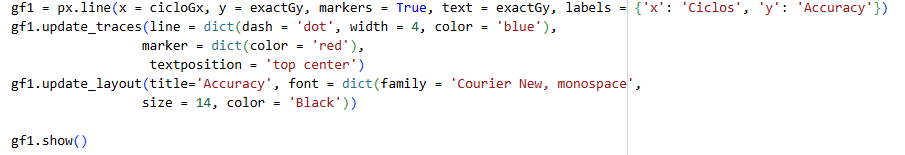

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
gf1 = px.line(x = cicloGx, y = exactGy, markers = True, text= exactGy, labels= {'x': 'Ciclos', 'y': 'Accuracy'})
gf1.update_traces(line = dict(dash = 'dot', width = 4, color = 'green'),
                  marker = dict(color = 'red'), 
                  textposition = 'top center')
gf1.update_layout(title = 'Accuracy', font = dict(family = 'Courier New, monospace', size = 14, color = 'Black'))
gf1.show()
# grafica el aprendizaje del modelo (precision)



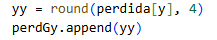

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultadofor y in range (len(perdida)):
perdGy = [] 
for y in range(len(perdida)):
    yy = round(perdida[y], 4)
    perdGy.append(yy)

cicloGx = list(range(1, len(perdGy) + 1))
# Prepara los datos de perdida para despues graficarlos

In [ ]:
print(cicloGx)
print(perdGy)

print("Longitud X:", len(cicloGx))
print("Longitud Y:", len(perdGy))

# imprime las longitudes, ya que deben coincidir

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
[0.0145, 0.0142, 0.0137, 0.0137, 0.0135, 0.0135, 0.0134, 0.0128, 0.0128, 0.0126, 0.0124, 0.0124, 0.0122, 0.012, 0.0118]
Longitud X: 15
Longitud Y: 15


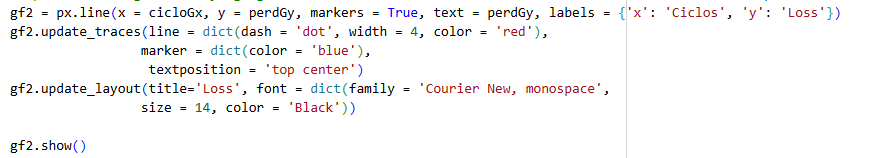

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
gf2 = px.line(x = cicloGx, y = perdGy, markers = True, text= perdGy, labels= {'x': 'Ciclos', 'y': 'Loss'})
gf2.update_traces(line = dict(dash = 'dot', width = 4, color = 'red'),
                  marker = dict(color = 'green'), 
                  textposition = 'top center')
gf2.update_layout(title = 'Loss', font = dict(family = 'Courier New, monospace', size = 14, color = 'Black'))
gf2.show()

# Genera la grafica de perdida (que tanto se equivoca el modelo)


## Evaluación del modelo

image.png

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
test_loss, test_acc = model.evaluate(x_test, y_test)
# Evalua el rendimiento del modelo con las imagenes de prueba, obteniendo su perdida (Loss) y exactitud (Accuracy).

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9899 - loss: 0.0344


image.png

In [ ]:
#Captura el código fuente y agrega los comentarios describiendo la funcionalidad del mismo e interpreta el resultado
print('Precision: ', test_acc)
# imprime la precision del modelo usado con datos de prueba

Precision:  0.9898999929428101
